# Collecting data from custom graphs for proximal learning

```
         For: Jakob Zeitler & Christophe Muller
      Author: Juan L. Gamella
Last updated: 2026.04.23
```
For questions, write us at support@causalchamber.ai or through any of the provided support channels.

To run this notebook you will also need matplotlib, numpy, and seaborn, although these are not a dependency of the `causalchamber` package.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Connect to the Remote Lab

If you haven't already, set up your credentials following these [instructions](https://docs.causalchamber.ai/remote-lab/quickstart).

In [2]:
import causalchamber.lab as lab
rlab = lab.Lab('.credentials')

/Users/jakobzeitler/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(



Fetching list of available datasets from https://causalchamber.s3.eu-central-1.amazonaws.com/downloadables/directory.yaml ... done.
If you use our datasets or models for your work please consider citing:

@article{gamella2024chamber,
  title={The Causal Chambers: Real Physical Systems as a Testbed for AI Methodology},
  author={Gamella, Juan L. and B"uhlmann, Peter and Peters, Jonas},
  journal={arXiv preprint arXiv:2404.11341},
  year={2024}
}



ModuleNotFoundError: No module named 'causalchamber.lab'

## Defining a custom graph

You can exclude the variables `current_ls_raw`, `ir_1`, `vis_1` and `ir_2` from your dataset (i.e., unobserved), and the graph collapses to the star-shaped graph from Tchetgen et al. (2009, [PDF](https://arxiv.org/pdf/2009.10982)).

You are free to define the functions `f_1`, ..., `f_4` how you wish (or even turn them off). See some examples below.

Define how sampling is done with the functions `sample_standard` or `sample_linked` below. You can edit them to suit your needs or sample from other graphs.

**Why two functions?**

- `sample_standard` uses the chamber in the `standard` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf)) configuration, i.e., the digital effects (green edges) are implemented by you in the `sample_standard` function.
- `sample_linked` uses the configurations `linked_leds` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf)) or `linked_leds_sigmoid` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf)), where the functions `f2` and `f3` are already implemented by the microcontroller of the chamber. This means slightly faster sampling, but limits the forms of these functions to a clamped linear function or a logistic function (sigmoid). You can change the paramters of these functions (see interventions below).

To learn more about hardware configurations, see [here](https://docs.causalchamber.ai/the-chambers/how-they-work#hardware-configurations).

#### Interventions

For sensor measurements (marked with M), only perturbations are possible (by changing the sensor parameters). See the [documentation](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf) for the complete chamber graph and variable descriptions.

For input nodes (marked with I).

- If running the `standard` configuration: You can perform any intervention type on input nodes, just adjust the `sample_standard` function below
- If running the `linked_leds` or `linked_leds_sigmoid` configurations: use the variables [`slope/intercept_f2/3, intercept_f2/3`](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf) or [`l/k/x0/b_f2/f3`](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf) to perform interventions on `led_2_uv` and `led_3_uv`.

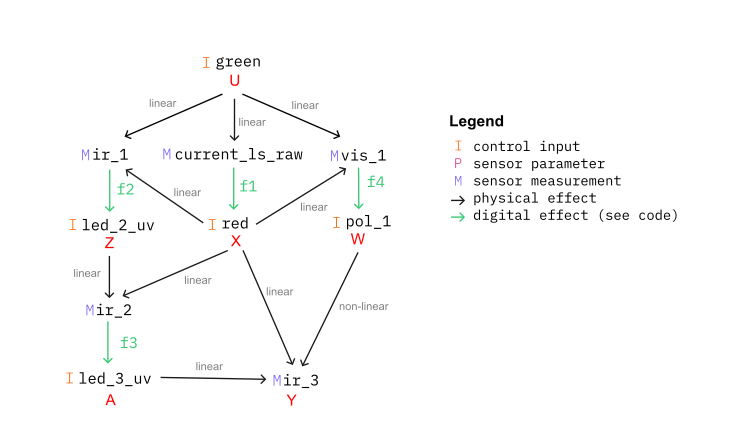

### Defining `f_1`, ..., `f_4`

You can use whatever you like, but here are two pre-implemented ones: a clamped linear function and a parametrizable sigmoid (the logistic function).

#### Clamped linear function

In [ ]:
def clamped(x, a, b, lo, hi):
    return np.maximum(lo,np.minimum(hi, a*x + b))

The parameters `a`,`b` are the slope and intercept, `lo`,`hi` set the max/min values (at which clamping ocurrs).

#### Logistic function

In [ ]:
def logistic(x, l, k, x0, b):
    return l / (1 + np.exp(-k * (x-x0))) + b    

The parameters `l`,`k`,`x0` and `b` allow you to change the shape of the function. See appendix for different function shapes.

### Collecting data

To understand the chamber / batch calls, please see the [documentation](https://docs.causalchamber.ai/remote-lab/running-a-real-time-experiment).

To sample using the `standard` configuration of the chamber ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf)).

In [ ]:
def sample_standard(chamber, green, f1, f2, f3, f4):
    # Step 1: Set green, then measure
    batch = chamber.new_batch()
    batch.set('green', green)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: Set red (from step 1's measurement), then measure
    current_ls_raw = df.current_ls_raw
    red = round(f1(current_ls_raw))
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Set led_2_uv and pol_1 (from step 2's measurement), then measure
    ir_1 = df.ir_1
    led_2_uv = round(f2(ir_1))
    vis_1 = df.vis_1
    pol_1 = f4(vis_1)
    batch = chamber.new_batch()
    batch.set('led_2_uv', led_2_uv)
    batch.set('pol_1', pol_1)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 4: Set led_3_uv (from step 3's measurement), then measure
    ir_2 = df.ir_2
    led_3_uv = round(f3(ir_2))
    batch = chamber.new_batch()
    batch.set('led_3_uv', led_3_uv)
    batch.measure(n=1)
    df = batch.submit().iloc[0]
    ir_3 = df.ir_3

    # Return data
    return pd.DataFrame({
        'green': [green],
        'current_ls_raw': [current_ls_raw],
        'red': [red],        
        'vis_1': [vis_1],
        'pol_1': [pol_1],
        'ir_1': [ir_1],
        'led_2_uv': [led_2_uv],
        'ir_2': [ir_2],
        'led_3_uv': [led_3_uv],
        'ir_3': [ir_3]
    })

To sample using the `linked_leds` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf)) or `linked_leds_sigmoid` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf)) configurations of the chamber.

In [ ]:
def sample_linked(chamber, green, f1, f4):
    # Step 1: Set green, then measure
    batch = chamber.new_batch()
    batch.set('green', green)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: Set red (from step 1's measurement), then measure
    current_ls_raw = df.current_ls_raw
    red = round(f1(current_ls_raw))    
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Set pol_1 (from step 2's measurement), then measure
    # NOTE: f2, f3 are computed by the chamber itself
    vis_1 = df.vis_1
    pol_1 = f4(vis_1)
    batch = chamber.new_batch()
    batch.set('pol_1', pol_1)
    batch.measure(n=1)
    df_last = batch.submit().iloc[0]

    # Return data
    return pd.DataFrame({
        'green': [green],
        'current_ls_raw': [current_ls_raw],
        'red': [red],
        'vis_1': [vis_1],
        'pol_1': [pol_1],
        'ir_1': [df_last.ir_1],
        'led_2_uv': [df_last.led_2_uv],
        'ir_2': [df_last.ir_2],
        'led_3_uv': [df_last.led_3_uv],
        'ir_3': [df_last.ir_3]
    })

Now, to collect a fresh dataset with `n` datapoints (after resetting the chamber)

In [ ]:
CHAMBER_ID = 'lt-demo-ch4lu'

def sample(green, config, f1, f2, f3, f4, verbose=True):
    chamber = lab.Chamber(CHAMBER_ID, config, credentials_file = '.credentials')
    dfs = []
    n = len(green)
    for i in range(n):
        print(f'Collecting datapoint {i+1}/{n}', end="\r") if verbose else None
        if config == 'standard':
            observation = sample_standard(chamber, green[i], f1, f2, f3, f4)
        elif config in ['linked_leds', 'linked_leds_sigmoid']:
            observation = sample_linked(chamber, green[i], f1, f4)
        else:
            raise Exception(f"Unrecognized chamber config {CHAMBER_CONFIG}")
        # Save the datapoint
        dfs.append(observation)
    return pd.concat(dfs, ignore_index=True)

## Example dataset

Let's begin by defining the functions. The parameters for `f2` and `f3` below are taken from the [linked_leds](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf) and [linked_leds_sigmoid](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf) configurations, where the chamber itself these functions. If you decide on this graph, you can switch `CHAMBER_CONFIG` to these configurations for faster data collection; if in doubt, ask Juan.

In [ ]:
f1 = lambda x: logistic(x, l=255, k=2e-3, x0=-18250.0, b=0) # Logistic

f4 = lambda x: logistic(x, l=180, k=2e-3, x0=4000, b=-90)

# f2 and f3 as defined in the linked_leds and linked_leds_sigmoid configurations (see above).
# If using these chamber configs, these functions are computed by the chamber, which is a bit faster

# f2 = lambda x: logistic(x, l=4095, k=2e-4, x0=32768, b=0) # Logistic
f2 = lambda x: clamped(x, 0.0624, 0, 0, 4095) # linear clamped

# f3 = lambda x: logistic(x, l=4095, k=1e-3, x0=5000, b=0) # Logistic
f3 = lambda x: clamped(x, 5*0.0624, 0, 0, 4095) # linear clamped


Now, sample data for green (our source node) and run the sample function

**linked_leds** configuration

In [ ]:
%%time
# Total datapoints
N = 300

# Sample green
rng = np.random.default_rng(981264976135)
green = rng.integers(0, 256, size=N)

df = sample(green, 'linked_leds', f1, f2, f3, f4)
# df = sample(green, 'linked_leds_sigmoid', f1, f2, f3, f4)

In [ ]:
sns.pairplot(df)

**standard** configuration

In [ ]:
%%time
# Total datapoints
N = 300

# Sample green
rng = np.random.default_rng(981264976135)
green = rng.integers(0, 256, size=N)

df_std = sample(green, 'standard', f1, f2, f3, f4)

In [ ]:
sns.pairplot(df_std)

## Appendix

The logistic function for different values of the parameters. You can use this code to experiment with different values.

In [ ]:
colors = ["#648FFF", "#785EF0", "#DC267F", "#FE6100", "#FFB000", "black"]  # IBM colorblind palette

curves = [
    ({"l": 4095, "k": 2e-4, "x0": 32768, "b": 0}, "default params."),
    ({"l": 4095, "k": 1e-4, "x0": 20_000, "b": 0}, "k = 1e-4"),
    ({"l": 4095, "k": -2e-4, "x0": 32768, "b": 0}, "k = -2e-4"),
    ({"l": 25_000, "k": 1e-5, "x0": 32768, "b": -10450}, "k = 1e-5, b = -10450"),
    ({"l": 4095, "k": 1e-2, "x0": 25_000, "b": 0}, "k = 1e-2, x0 = 25e4"),
    ({"l": 4095, "k": 0, "x0": 32768, "b": 0}, "k = 0"),
]

x = np.linspace(0, 2**16 - 1, 10_000)

fig, ax = plt.subplots(figsize=(4.7, 3.8))

for i, (params, label) in enumerate(curves):
    ax.plot(x, logistic(x, **params), color=colors[i], label=label)

ax.axhline(0, color="gray", linestyle=":")
ax.axhline(4095, color="gray", linestyle=":")
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
ax.set_yticks([0, 4095])
ax.legend(fontsize=9, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2)
ax.set_xlabel('x', fontsize=11)
ax.set_ylabel('$f_n$(x)', rotation=0, ha='right', fontsize=11)
# plt.savefig('sigmoids_params.pdf', dpi=200, bbox_inches='tight')